Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MEMULAI PRA-PEMROSESAN - HANYA POSE DEPAN
FILTER: Hanya memproses file dengan nama 'depan'
Pipeline: Asli → Brightness/Contrast → Histogram Equalization
          → Spatial Filtering → Dithering

Mencari file dengan nama 'depan'...
File 'depan' ditemukan: 9 gambar

File yang akan diproses:
  - Muhammad Syafiq Aldiansyah/terang/depan.jpg
  - Muhammad Syafiq Aldiansyah/gelap/depan.jpg
  - Muhammad Syafiq Aldiansyah/bayang/depan.jpg
  - Romy Mahardika Pangestu .L/gelap/depan.jpg
  - Romy Mahardika Pangestu .L/bayang/depan.jpg
  - Romy Mahardika Pangestu .L/terang/depan.jpg
  - Febriansyah Adi Nugroho/gelap/depan.jpg
  - Febriansyah Adi Nugroho/terang/depan.jpg
  - Febriansyah Adi Nugroho/bayang/depan.jpg


Memulai processing file DEPAN...
--------------------------------------------------

PROSES [1/9]
File: depan.jpg
  Memproses: Muhammad Syafiq Aldiansyah - te

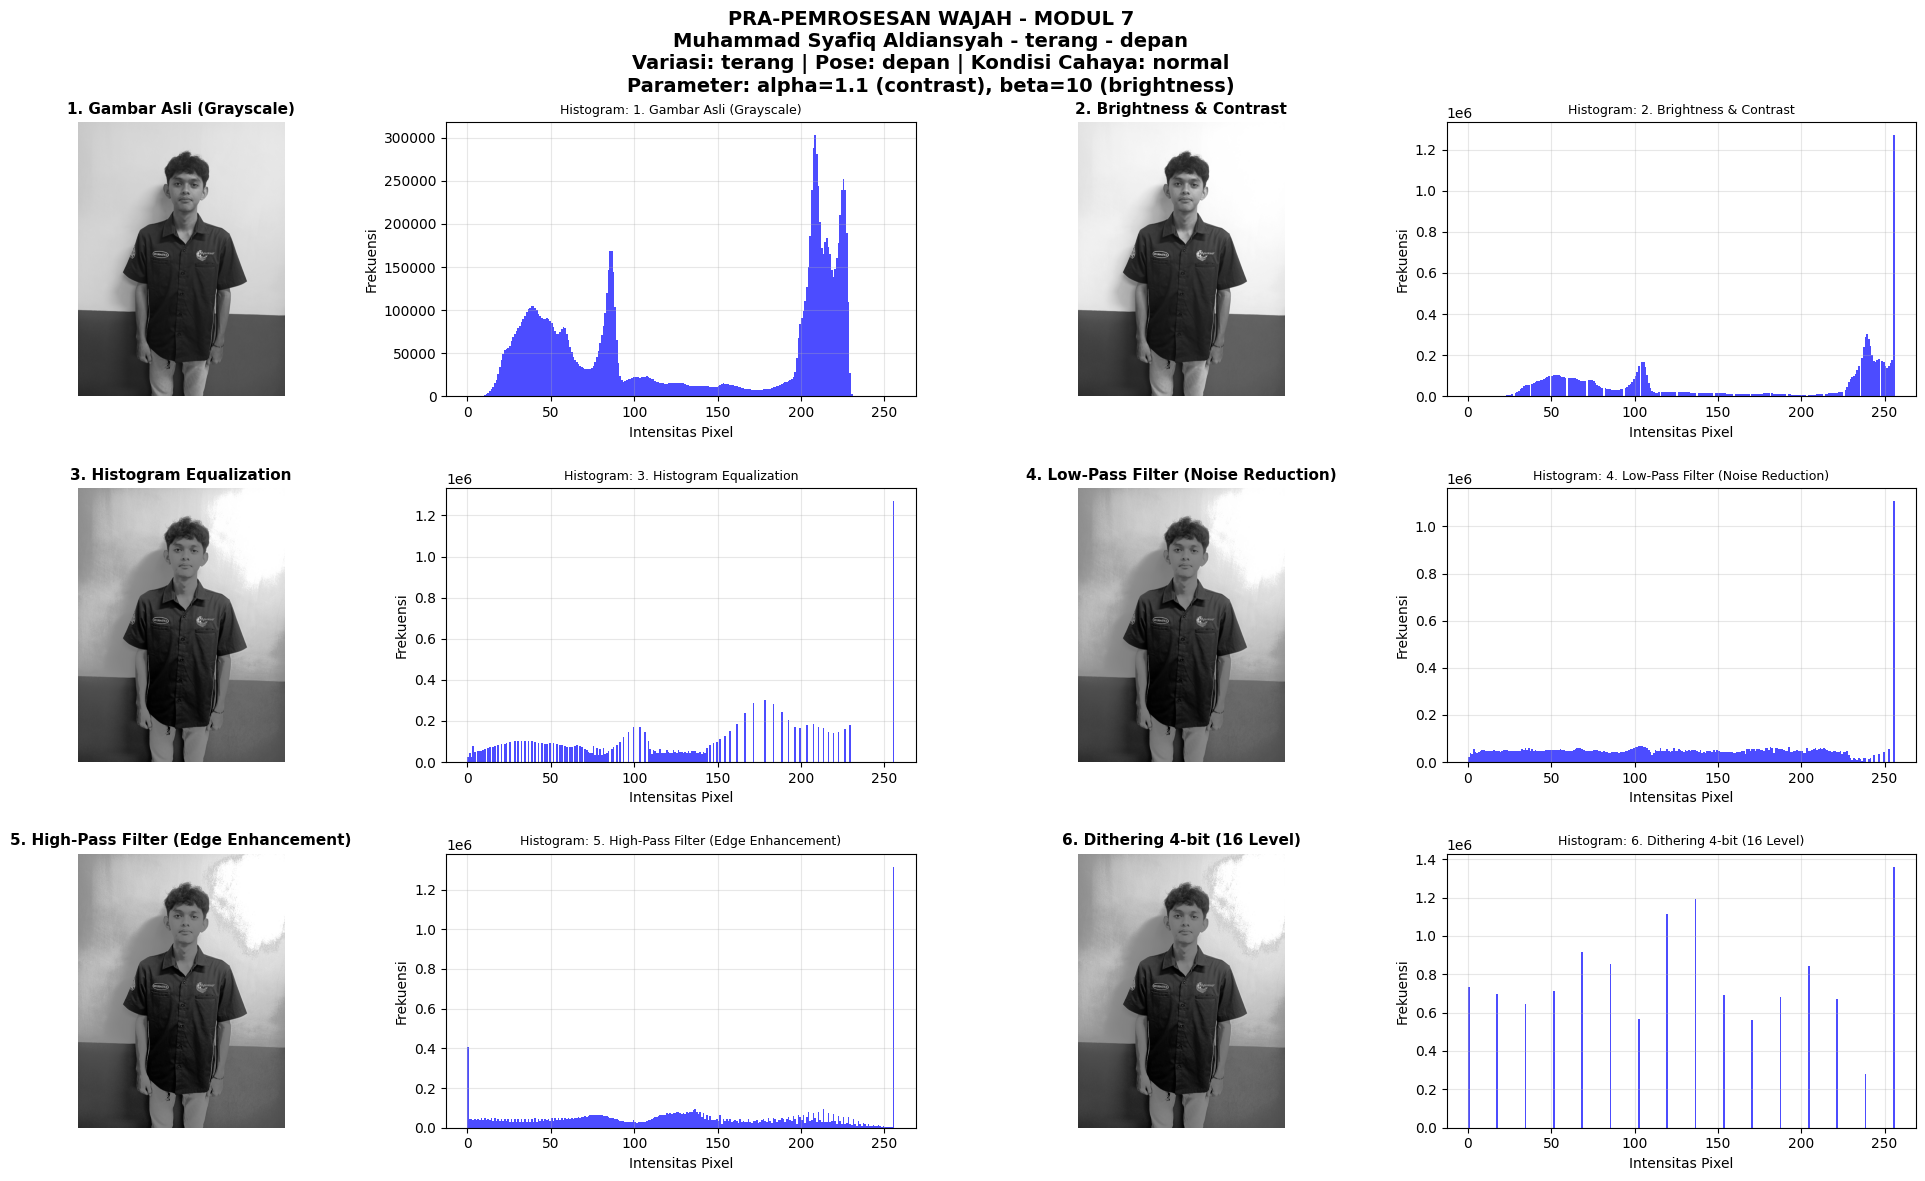

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [2/9]
File: depan.jpg
  Memproses: Muhammad Syafiq Aldiansyah - gelap - depan
  Kondisi: normal, Brightness: 116.0
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


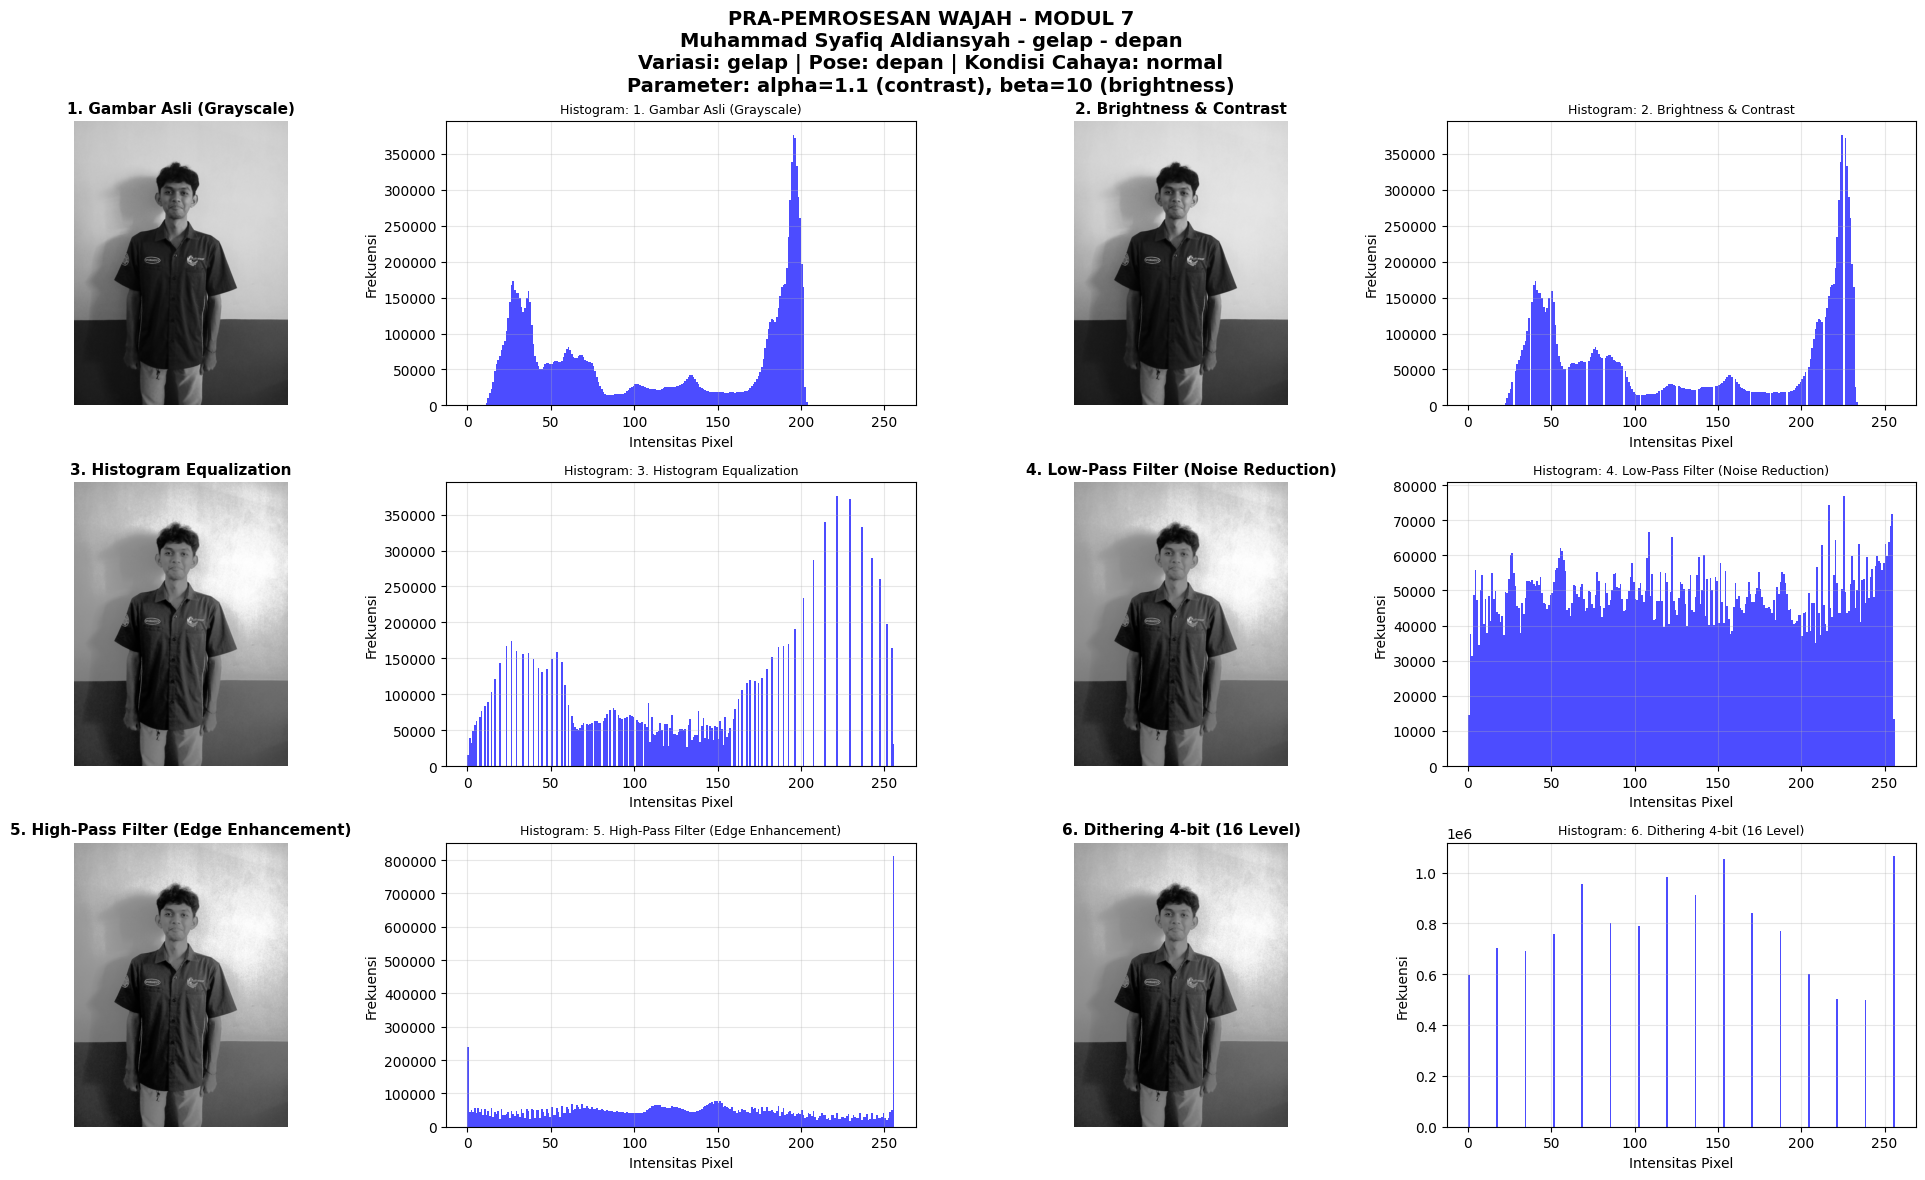

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [3/9]
File: depan.jpg
  Memproses: Muhammad Syafiq Aldiansyah - bayang - depan
  Kondisi: gelap, Brightness: 76.1
  Parameter: alpha=1.4 (contrast), beta=50 (brightness)


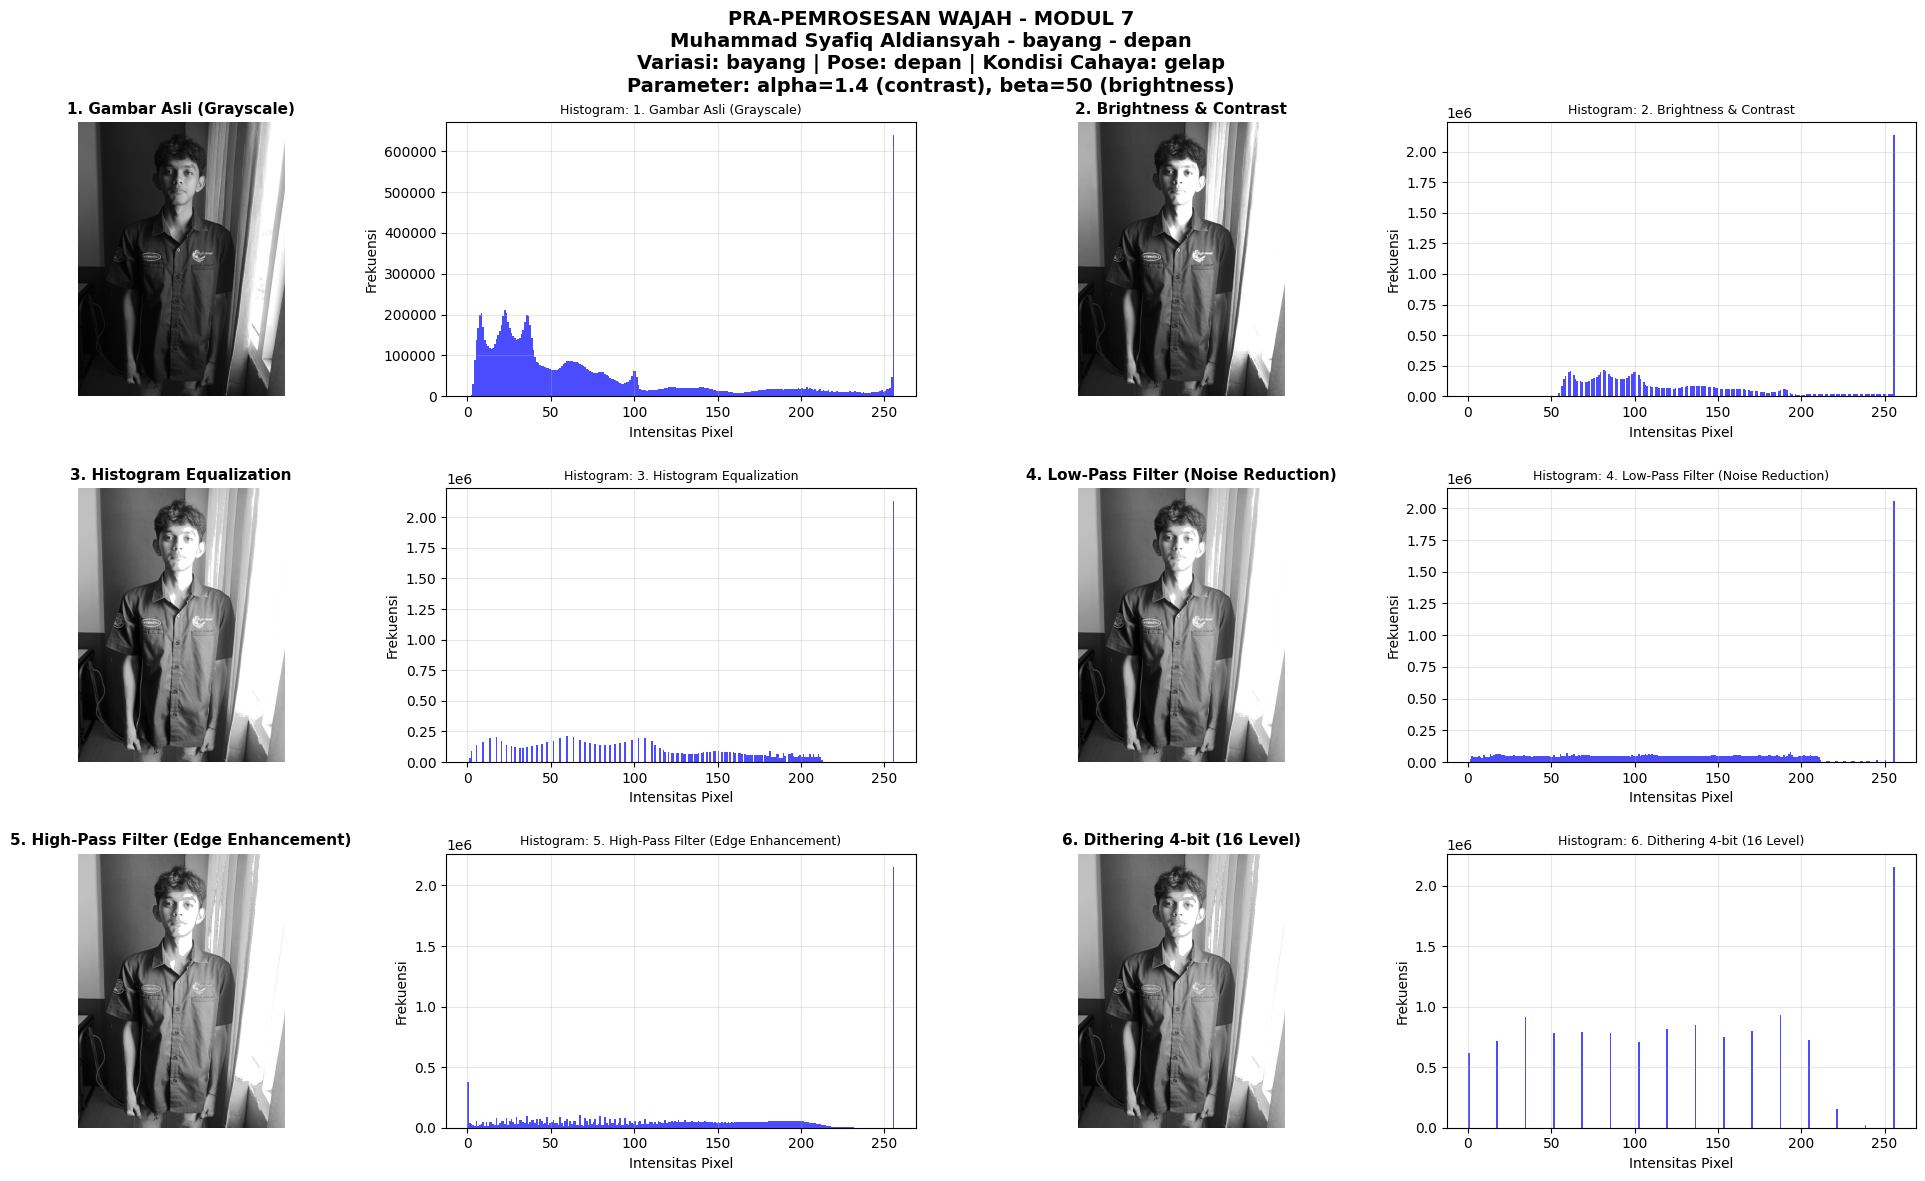

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [4/9]
File: depan.jpg
  Memproses: Romy Mahardika Pangestu .L - gelap - depan
  Kondisi: normal, Brightness: 153.9
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


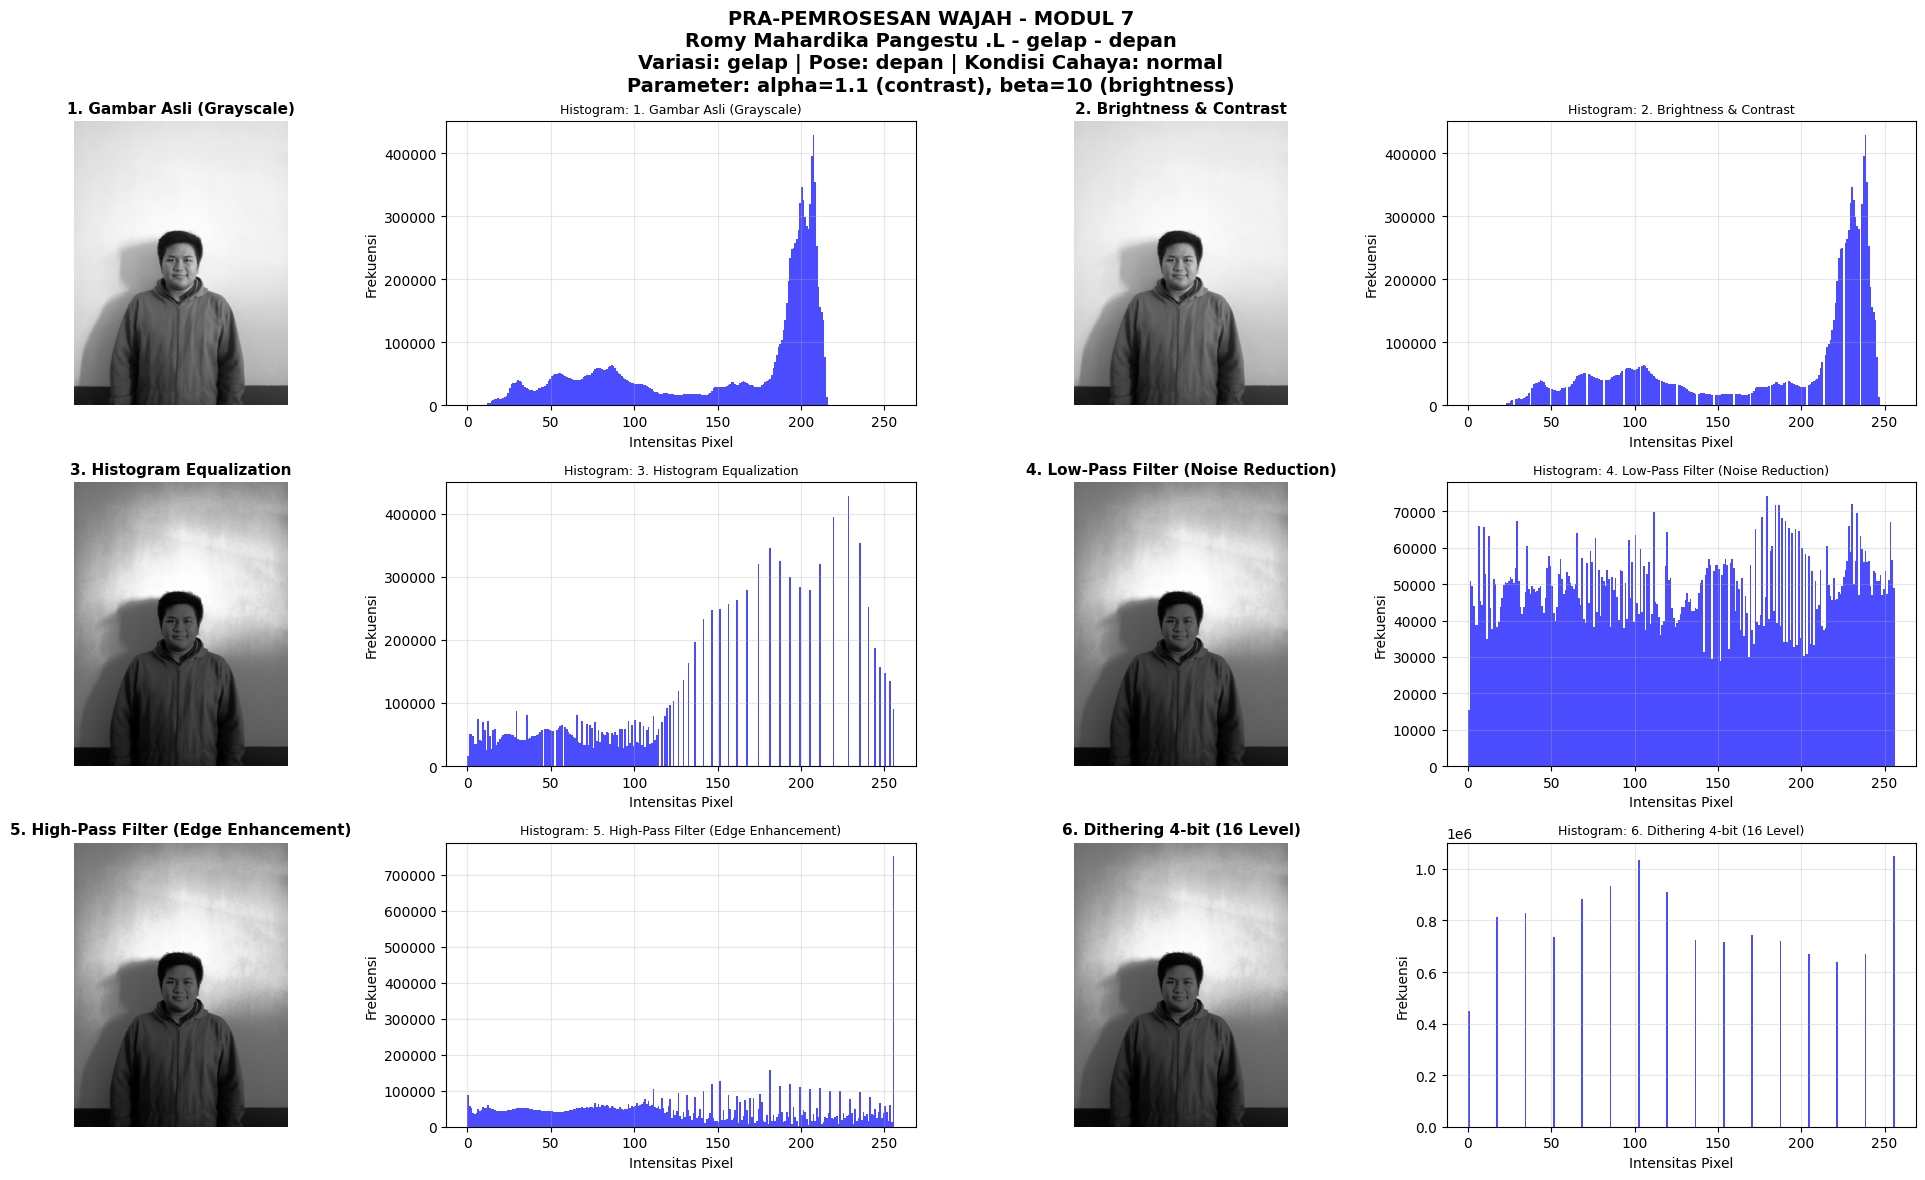

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [5/9]
File: depan.jpg
  Memproses: Romy Mahardika Pangestu .L - bayang - depan
  Kondisi: normal, Brightness: 84.3
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


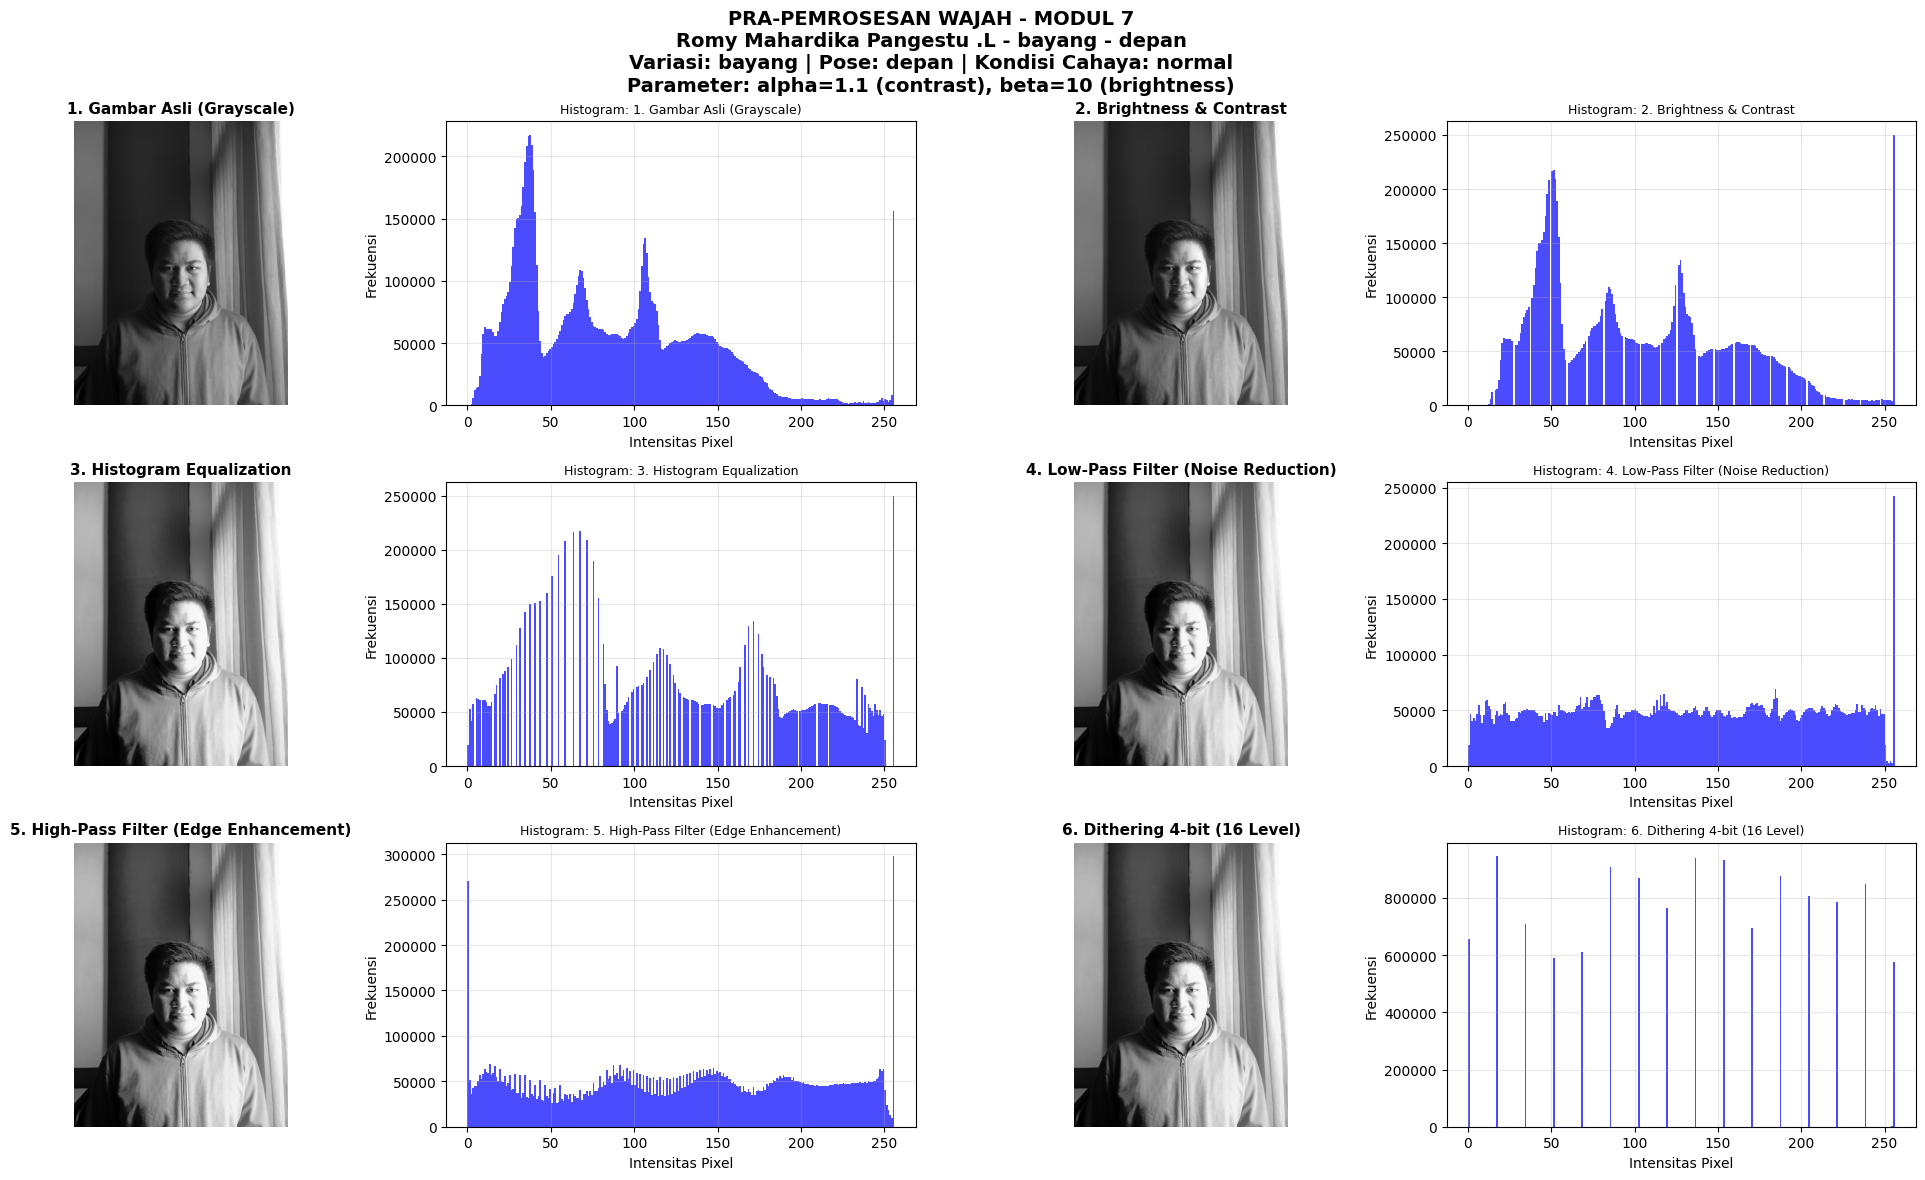

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [6/9]
File: depan.jpg
  Memproses: Romy Mahardika Pangestu .L - terang - depan
  Kondisi: normal, Brightness: 168.3
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


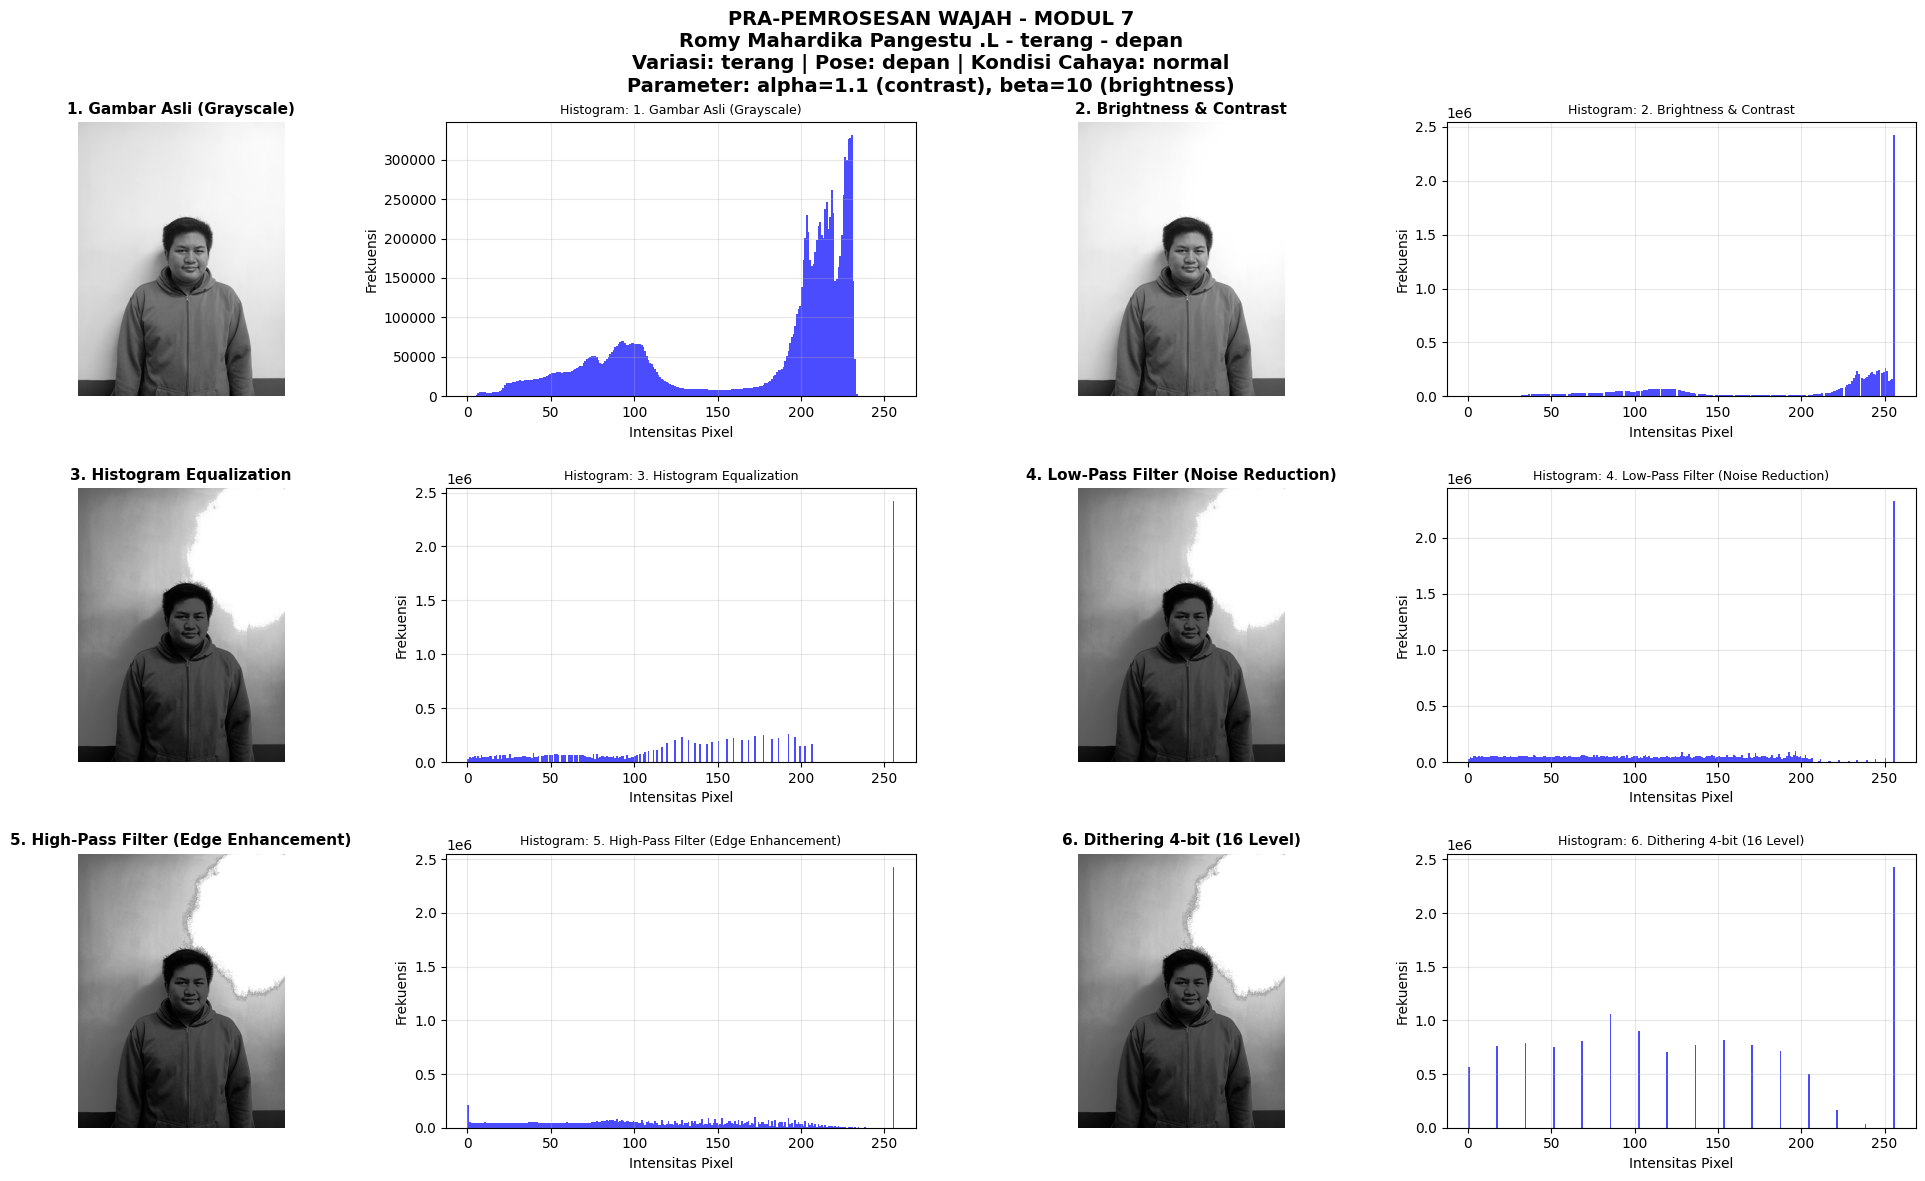

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [7/9]
File: depan.jpg
  Memproses: Febriansyah Adi Nugroho - gelap - depan
  Kondisi: normal, Brightness: 134.2
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


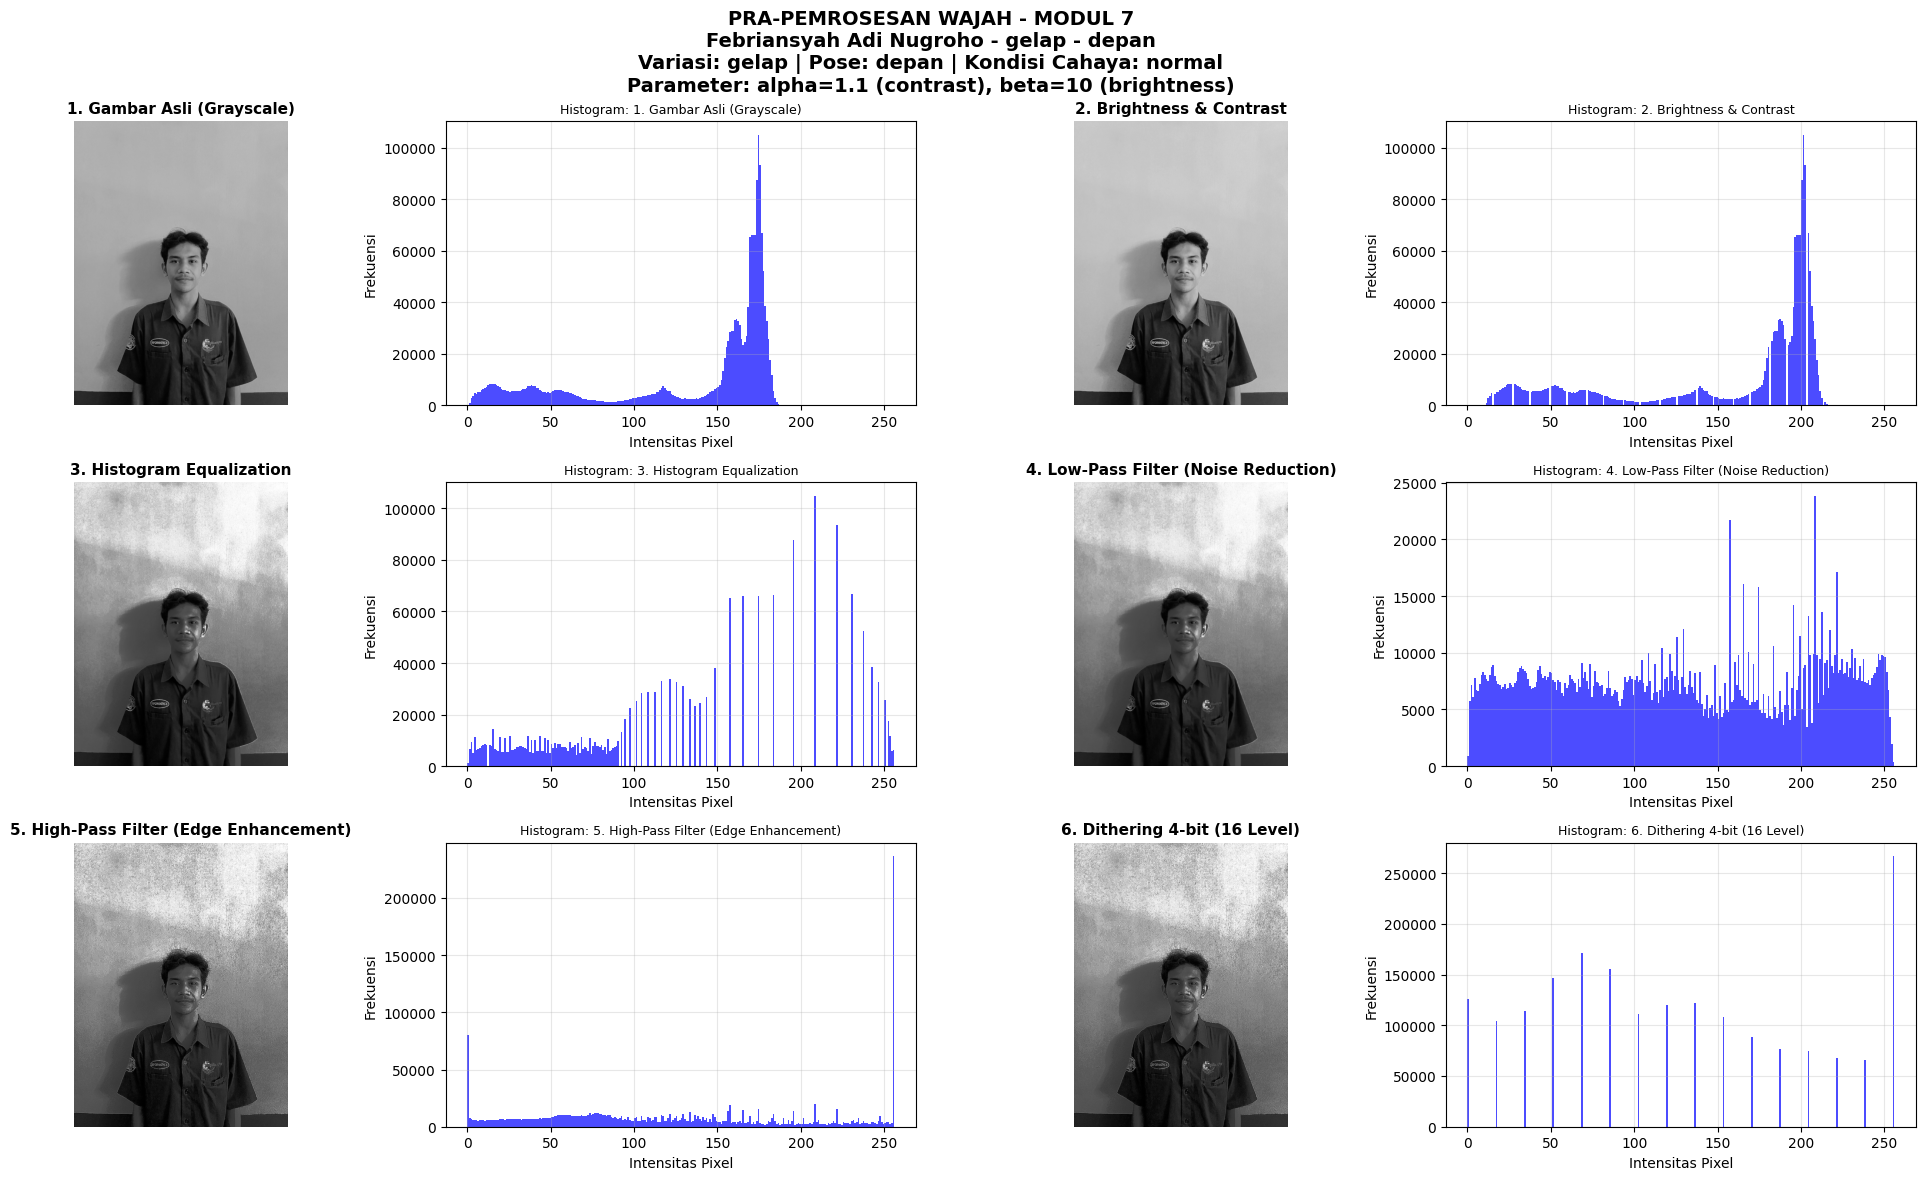

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [8/9]
File: depan.jpg
  Memproses: Febriansyah Adi Nugroho - terang - depan
  Kondisi: normal, Brightness: 179.9
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


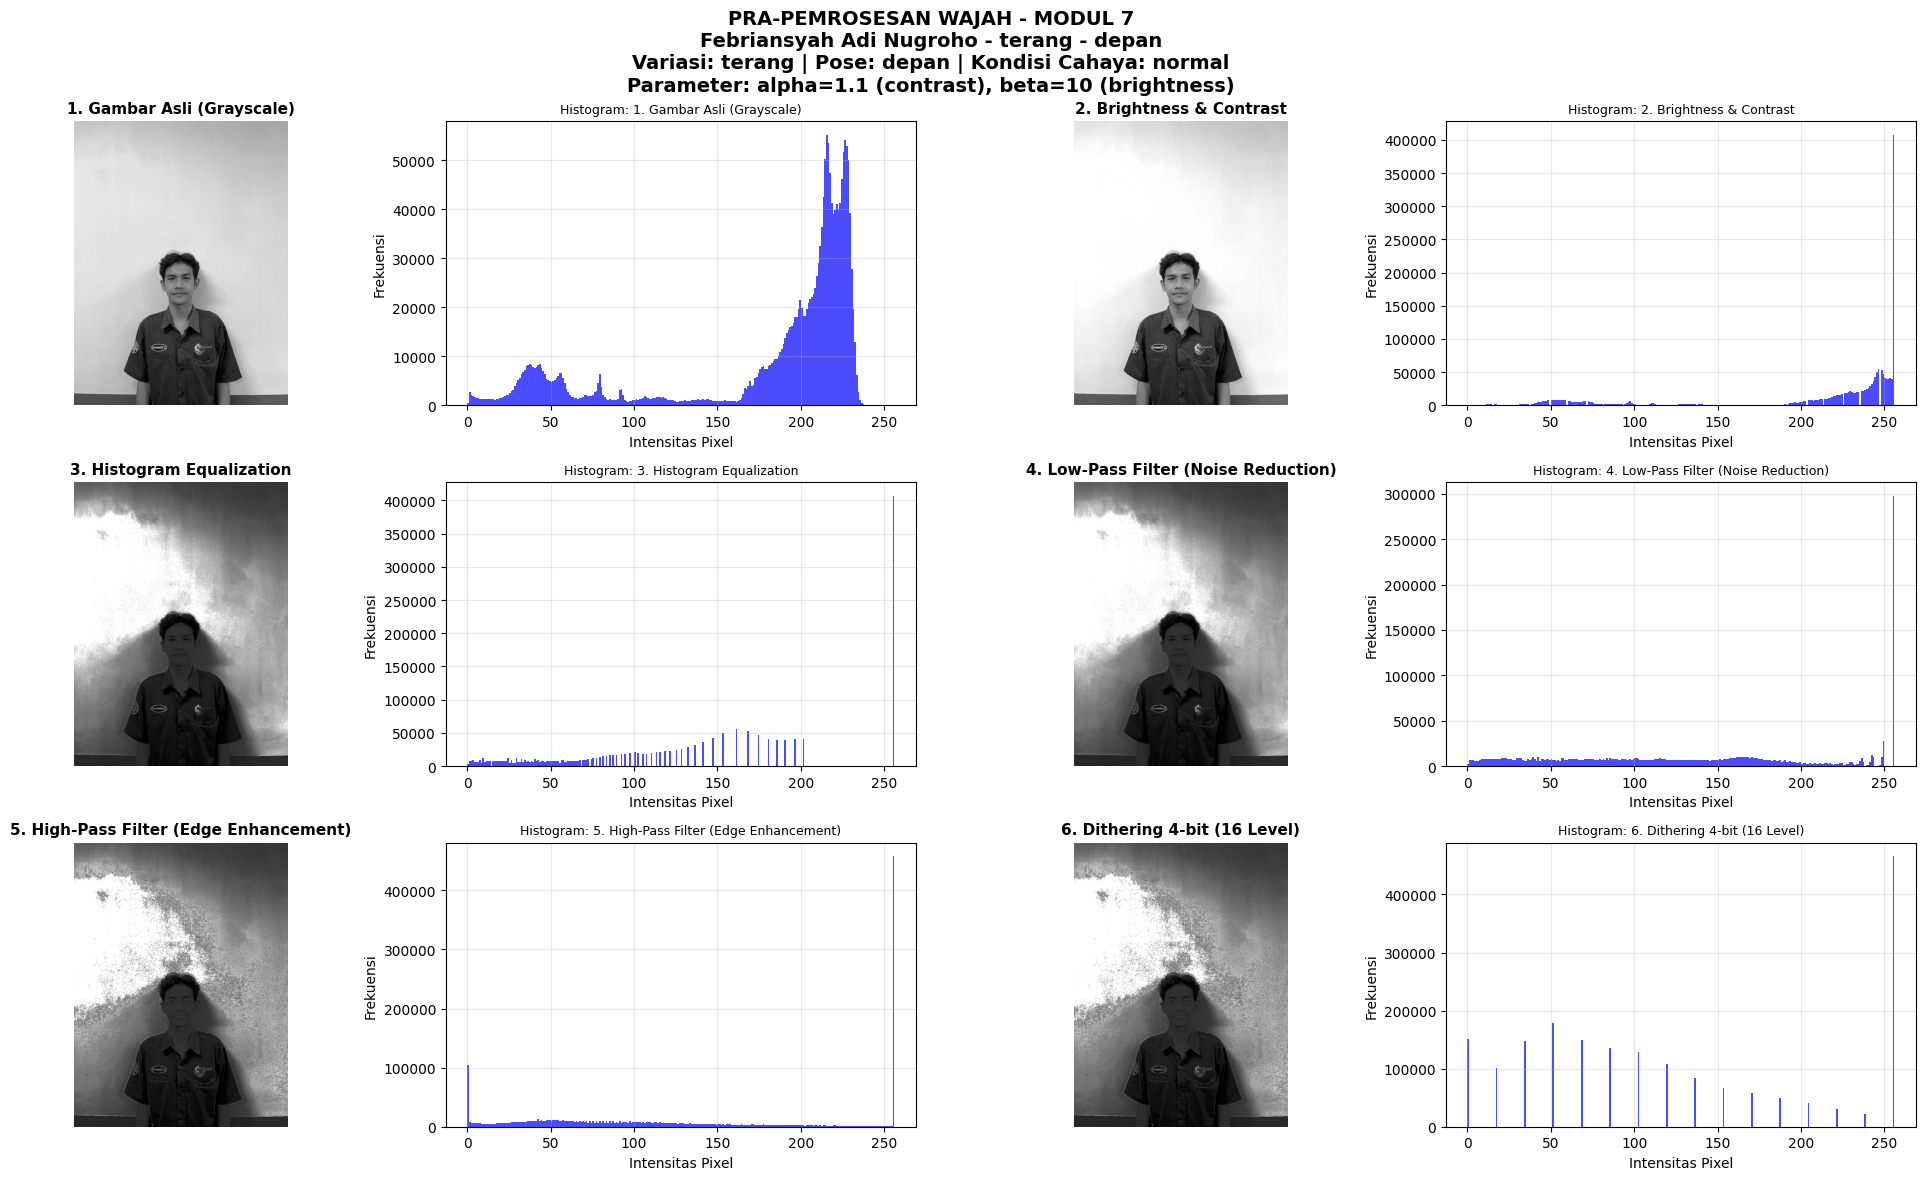

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

PROSES [9/9]
File: depan.jpg
  Memproses: Febriansyah Adi Nugroho - bayang - depan
  Kondisi: normal, Brightness: 93.7
  Parameter: alpha=1.1 (contrast), beta=10 (brightness)


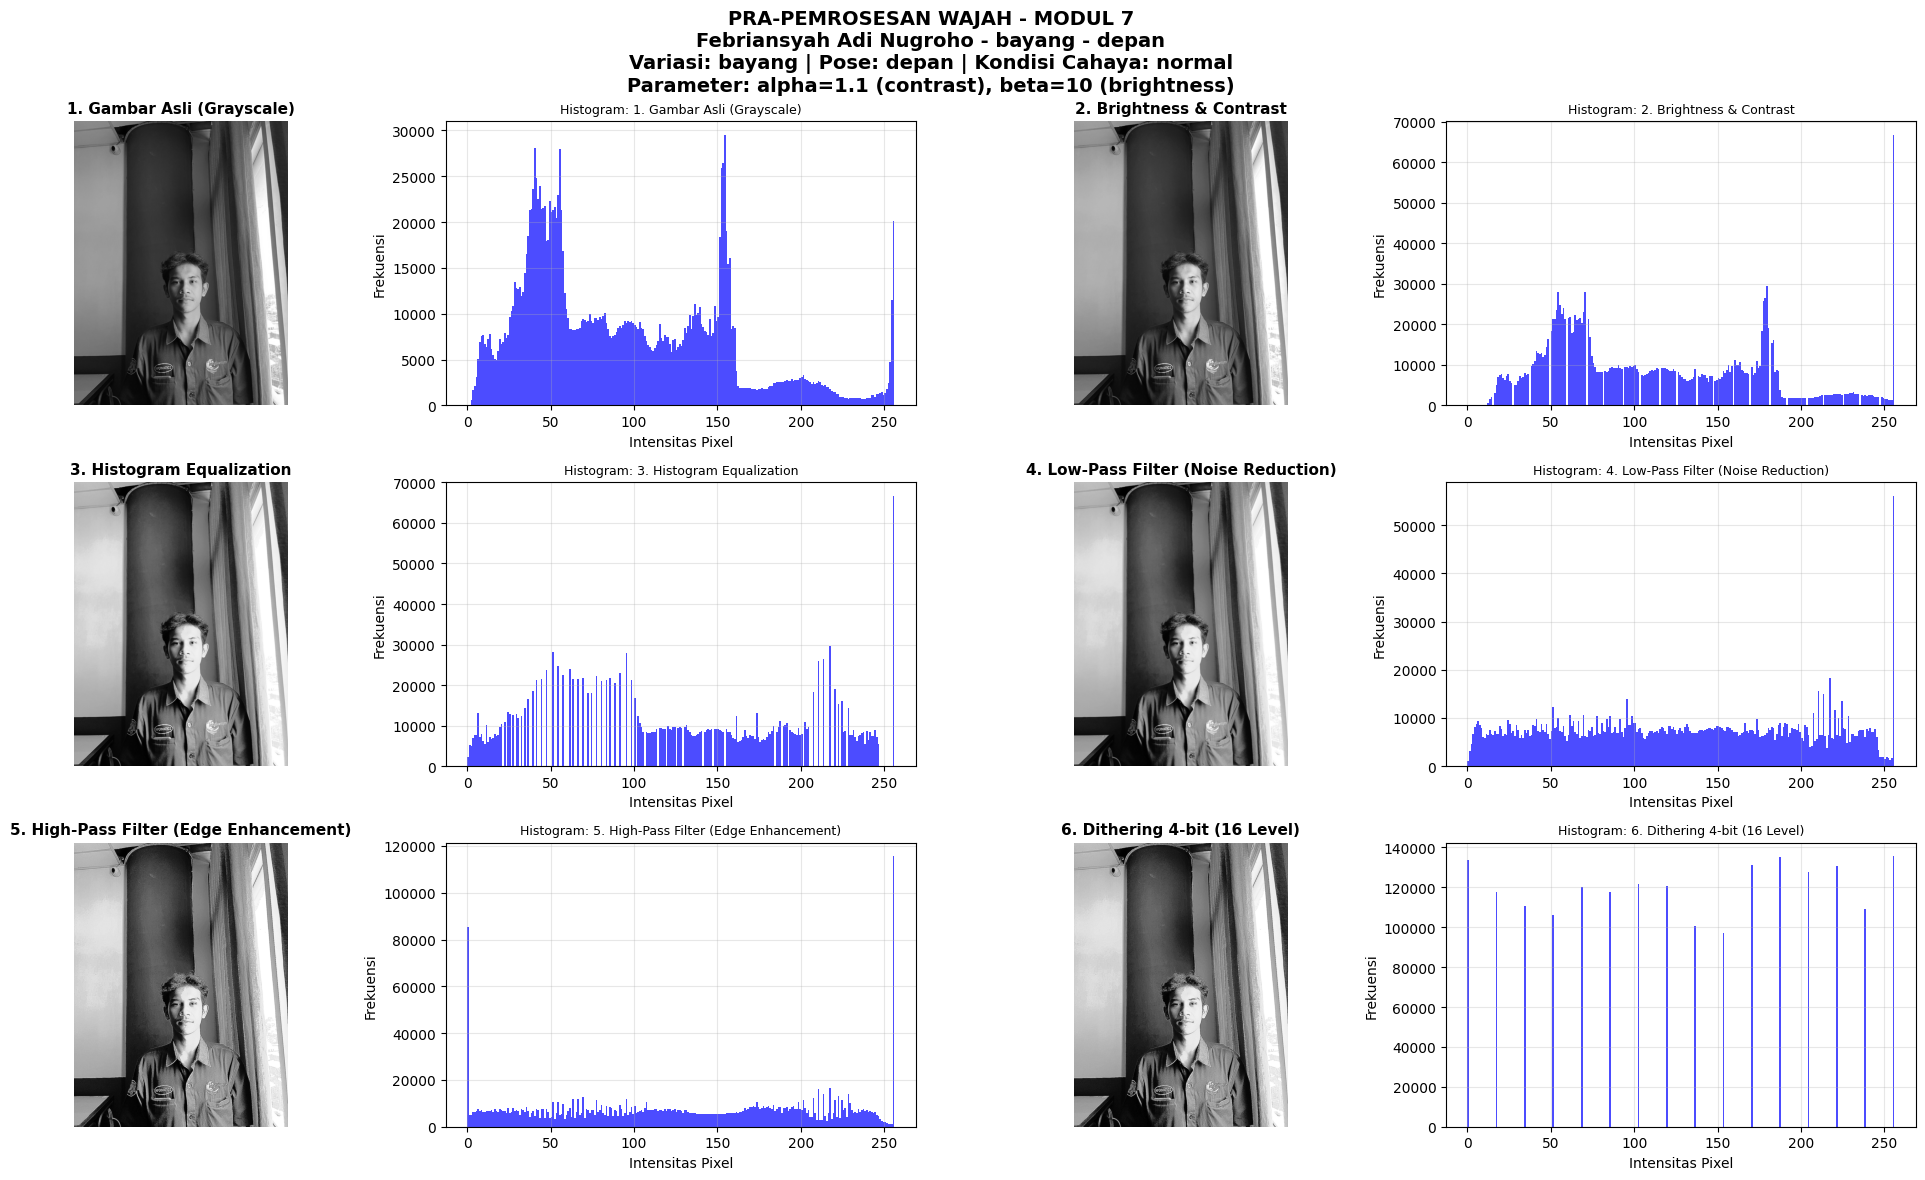

  Status: Berhasil diproses + ANALISIS DITAMPILKAN
--------------------------------------------------

HASIL AKHIR PRA-PEMROSESAN
Total file 'depan' diproses: 9
Gambar berhasil: 9
Gambar gagal: 0
Rate keberhasilan: 100.0%

Keterangan:
- HANYA file dengan nama 'depan' yang diproses
- File dengan pose lain (kanan/kiri/atas/bawah) DIABAIKAN
- Setiap file diproses melalui pipeline lengkap
- Analisis visual ditampilkan untuk semua file yang diproses

Tahapan processing:
1. Brightness & Contrast Adjustment
2. Histogram Equalization
3. Spatial Filtering (Low-pass & High-pass)
4. Floyd-Steinberg Dithering (4-bit)


In [ ]:
# ==========================================================
# MODUL 7 - PRA-PEMROSESAN CITRA WAJAH UNTUK FACE RECOGNITION
# ==========================================================
# Tujuan: Menganalisis dan meningkatkan kualitas citra wajah
# hanya untuk gambar dengan pose DEPAN untuk efisiensi processing
# ==========================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import drive

# Mount Google Drive untuk mengakses dataset
drive.mount('/content/drive')

# ==========================================================
# KONFIGURASI PATH DAN PARAMETER
# ==========================================================

# Path menuju folder dataset wajah
dataset_root = "/content/drive/MyDrive/PCVK/DatasetP7/"

# ==========================================================
# FUNGSI DITHERING FLOYD-STEINBERG (MODUL 6)
# ==========================================================

def floyd_steinberg_dithering(image, bit_depth=4):
    """
    Menerapkan algoritma Floyd-Steinberg dithering untuk mengurangi kedalaman bit
    """
    # Konversi ke grayscale jika gambar berwarna
    if len(image.shape) == 3:
        img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        img_gray = image.copy()

    # Konversi ke float untuk perhitungan presisi
    img_dither = img_gray.astype(float)
    height, width = img_dither.shape

    # Hitung jumlah level kuantisasi berdasarkan bit depth
    levels = 2 ** bit_depth
    step_size = 255.0 / (levels - 1)

    # Iterasi melalui setiap pixel dalam gambar
    for y in range(height - 1):
        for x in range(1, width - 1):
            old_pixel = img_dither[y, x]
            new_pixel = round(old_pixel / step_size) * step_size
            img_dither[y, x] = new_pixel
            quant_error = old_pixel - new_pixel

            # Sebarkan error ke pixel tetangga
            img_dither[y, x + 1] += quant_error * 7 / 16
            img_dither[y + 1, x - 1] += quant_error * 3 / 16
            img_dither[y + 1, x] += quant_error * 5 / 16
            img_dither[y + 1, x + 1] += quant_error * 1 / 16

    # Pastikan nilai pixel tetap dalam range 0-255
    img_dither = np.clip(img_dither, 0, 255)
    return img_dither.astype('uint8')

# ==========================================================
# FUNGSI PROSES SATU GAMBAR - PIPELINE UTAMA
# ==========================================================

def proses_satu_gambar(input_path):
    """
    Pipeline utama pra-pemrosesan untuk satu gambar wajah
    Urutan processing: Asli → Brightness/Contrast → Histogram Equalization → Filter → Dithering
    """

    # === TAHAP 1: LOAD GAMBAR ===
    img_bgr = cv2.imread(input_path)
    if img_bgr is None:
        print(f"  ERROR: Gagal membaca gambar {input_path}")
        return None

    # Dapatkan nama file untuk keperluan display
    filename = os.path.basename(input_path)

    # === TAHAP 2: EKSTRAK INFORMASI VARIASI & POSE ===
    rel_path = os.path.relpath(input_path, dataset_root)
    folder_parts = rel_path.split(os.sep)

    if len(folder_parts) >= 3:
        nama_orang = folder_parts[0]
        variasi = folder_parts[1]
        pose_file = folder_parts[2]
        pose = os.path.splitext(pose_file)[0]
        judul = f"{nama_orang} - {variasi} - {pose}"
    else:
        judul = filename
        variasi = "unknown"
        pose = "unknown"

    print(f"  Memproses: {judul}")

    # === TAHAP 3: KONVERSI KE GRAYSCALE ===
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # === TAHAP 4: ANALISIS KONDISI CAHAYA ===
    brightness_mean = np.mean(gray)

    if brightness_mean < 80:
        alpha, beta = 1.4, 50
        kondisi_cahaya = "gelap"
    elif brightness_mean > 180:
        alpha, beta = 0.7, -30
        kondisi_cahaya = "terlalu terang"
    else:
        alpha, beta = 1.1, 10
        kondisi_cahaya = "normal"

    print(f"  Kondisi: {kondisi_cahaya}, Brightness: {brightness_mean:.1f}")
    print(f"  Parameter: alpha={alpha} (contrast), beta={beta} (brightness)")

    # === TAHAP 5: BRIGHTNESS & CONTRAST ADJUSTMENT ===
    img_bc = cv2.convertScaleAbs(gray, alpha=alpha, beta=beta)

    # === TAHAP 6: HISTOGRAM EQUALIZATION ===
    img_he = cv2.equalizeHist(img_bc)

    # === TAHAP 7: SPATIAL FILTERING ===
    kernel_lp = np.ones((3,3), np.float32)/9
    img_lowpass = cv2.filter2D(img_he, -1, kernel_lp)

    kernel_hp = np.array([[-1,-1,-1],
                         [-1, 9,-1],
                         [-1,-1,-1]])
    img_highpass = cv2.filter2D(img_he, -1, kernel_hp)

    # === TAHAP 8: DITHERING ===
    img_dithered = floyd_steinberg_dithering(img_highpass, bit_depth=4)

    # === TAHAP 9: TAMPILKAN HASIL ===
    tampilkan_hasil_processing(
        gray, img_bc, img_he, img_lowpass, img_highpass, img_dithered,
        judul, alpha, beta, kondisi_cahaya, variasi, pose
    )

    return {
        'asli': gray,
        'brightness_contrast': img_bc,
        'histogram_equalized': img_he,
        'lowpass': img_lowpass,
        'highpass': img_highpass,
        'dithered': img_dithered
    }

# ==========================================================
# FUNGSI VISUALISASI HASIL PROCESSING
# ==========================================================

def tampilkan_hasil_processing(asli, bc, he, lowpass, highpass, dithered, judul,
                             alpha, beta, kondisi_cahaya, variasi, pose):
    """
    Menampilkan visualisasi lengkap semua tahapan processing
    """

    fig = plt.figure(figsize=(20, 12))
    fig.suptitle(
        f'PRA-PEMROSESAN WAJAH - MODUL 7\n'
        f'{judul}\n'
        f'Variasi: {variasi} | Pose: {pose} | Kondisi Cahaya: {kondisi_cahaya}\n'
        f'Parameter: alpha={alpha} (contrast), beta={beta} (brightness)',
        fontsize=14,
        fontweight='bold'
    )

    images = [asli, bc, he, lowpass, highpass, dithered]
    titles = [
        '1. Gambar Asli (Grayscale)',
        '2. Brightness & Contrast',
        '3. Histogram Equalization',
        '4. Low-Pass Filter (Noise Reduction)',
        '5. High-Pass Filter (Edge Enhancement)',
        '6. Dithering 4-bit (16 Level)'
    ]

    for i in range(6):
        plt.subplot(3, 4, 2*i + 1)
        plt.imshow(images[i], cmap='gray')
        plt.title(titles[i], fontsize=11, fontweight='bold')
        plt.axis('off')

        plt.subplot(3, 4, 2*i + 2)
        plt.hist(images[i].ravel(), bins=256, range=(0, 256), color='blue', alpha=0.7)
        plt.title(f'Histogram: {titles[i]}', fontsize=9)
        plt.xlabel('Intensitas Pixel')
        plt.ylabel('Frekuensi')
        plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# ==========================================================
# FUNGSI PROSES HANYA GAMBAR DEPAN
# ==========================================================

def proses_hanya_depan():
    """
    Hanya memproses gambar dengan nama file mengandung 'depan'
    Filter: hanya file dengan nama 'depan.jpg', 'depan.jpeg', 'depan.png'
    """

    print("MEMULAI PRA-PEMROSESAN - HANYA POSE DEPAN")
    print("=" * 60)
    print("FILTER: Hanya memproses file dengan nama 'depan'")
    print("Pipeline: Asli → Brightness/Contrast → Histogram Equalization")
    print("          → Spatial Filtering → Dithering")
    print("=" * 60)

    # === CARI FILE DENGAN NAMA DEPAN ===
    print("\nMencari file dengan nama 'depan'...")

    file_depan = []  # List untuk menyimpan path file yang akan diproses

    # Traverse semua folder untuk mencari file dengan nama 'depan'
    for root, dirs, files in os.walk(dataset_root):
        # Skip folder hidden
        if any(part.startswith('.') for part in root.split(os.sep)):
            continue

        for file in files:
            # Filter: hanya file yang namanya mengandung 'depan'
            # dan ekstensi gambar yang valid
            if ('depan' in file.lower() and
                file.lower().endswith(('.jpg', '.jpeg', '.png'))):
                full_path = os.path.join(root, file)
                file_depan.append(full_path)

    print(f"File 'depan' ditemukan: {len(file_depan)} gambar")

    # Tampilkan file yang akan diproses
    if file_depan:
        print("\nFile yang akan diproses:")
        for file_path in file_depan:
            rel_path = os.path.relpath(file_path, dataset_root)
            print(f"  - {rel_path}")
    else:
        print("Tidak ada file 'depan' ditemukan!")
        print("Pastikan ada file dengan nama 'depan.jpg', 'depan.jpeg', atau 'depan.png'")
        return

    print("\n" + "=" * 60)

    # === PROSES SETIAP FILE DEPAN ===
    print("\nMemulai processing file DEPAN...")
    print("-" * 50)

    gambar_berhasil = 0
    gambar_gagal = 0

    # Loop melalui semua file dengan nama 'depan'
    for i, file_path in enumerate(file_depan):
        filename = os.path.basename(file_path)

        print(f"\nPROSES [{i+1}/{len(file_depan)}]")
        print(f"File: {filename}")

        try:
            # Panggil fungsi utama processing
            # Semua file depan akan ditampilkan analisis visualnya
            hasil = proses_satu_gambar(file_path)

            if hasil is not None:
                gambar_berhasil += 1
                print("  Status: Berhasil diproses + ANALISIS DITAMPILKAN")
            else:
                gambar_gagal += 1
                print("  Status: Gagal diproses")

        except Exception as e:
            gambar_gagal += 1
            print(f"  ERROR: {str(e)}")

        print("-" * 50)

    # === TAMPILKAN RINGKASAN AKHIR ===
    print("\n" + "=" * 60)
    print("HASIL AKHIR PRA-PEMROSESAN")
    print("=" * 60)
    print(f"Total file 'depan' diproses: {len(file_depan)}")
    print(f"Gambar berhasil: {gambar_berhasil}")
    print(f"Gambar gagal: {gambar_gagal}")
    print(f"Rate keberhasilan: {(gambar_berhasil/len(file_depan))*100:.1f}%")

    print("\nKeterangan:")
    print("- HANYA file dengan nama 'depan' yang diproses")
    print("- File dengan pose lain (kanan/kiri/atas/bawah) DIABAIKAN")
    print("- Setiap file diproses melalui pipeline lengkap")
    print("- Analisis visual ditampilkan untuk semua file yang diproses")

    print("\nTahapan processing:")
    print("1. Brightness & Contrast Adjustment")
    print("2. Histogram Equalization")
    print("3. Spatial Filtering (Low-pass & High-pass)")
    print("4. Floyd-Steinberg Dithering (4-bit)")
    print("=" * 60)

# ==========================================================
# JALANKAN PROGRAM UTAMA
# ==========================================================

if __name__ == "__main__":
    """
    Entry point program. Hanya memproses file dengan pose DEPAN
    """
    # Jalankan fungsi yang hanya memproses file 'depan'
    proses_hanya_depan()

Bagian B - Analisis

Jawablah dalam bentuk narasi atau tabel analisis singkat:
1. Bagaimana perubahan nilai brightness dan contrast memengaruhi hasil histogram wajah
gelap?
Ketika citra wajah dengan pencahayaan gelap diproses menggunakan peningkatan brightness (beta = 50) dan contrast (alpha = 1.4), histogram yang semula menumpuk di area intensitas rendah (0-80) bergeser ke arah kanan.
Hal ini menyebabkan rentang intensitas menjadi lebih lebar dan distribusi piksel lebih merata. Secara visual, area wajah yang sebelumnya terlalu gelap (pipi dan dahi) menjadi lebih terlihat tanpa kehilangan detail penting seperti mata dan mulut.
Kesimpulannya, peningkatan brightness dan contrast mampu menormalkan pencahayaan wajah gelap dan memperbaiki keterbacaan fitur wajah pada tahap awal.

2. Apakah histogram equalization selalu memperbaiki detail wajah? Jelaskan alasannya dengan
contoh hasil Anda.
Tidak selalu.
Histogram Equalization (HE) bekerja dengan menyebarkan intensitas piksel agar mencakup seluruh rentang (0–255). Pada citra dengan kontras rendah, metode ini meningkatkan perbedaan terang–gelap sehingga kontur wajah (hidung, mata, bibir) menjadi lebih jelas.
Namun, pada wajah yang sudah memiliki pencahayaan cukup baik, HE dapat menimbulkan noise berlebihan atau efek “over-enhanced” pada area kulit yang halus, sehingga tekstur tampak kasar.
Jadi, efektivitas HE tergantung kondisi awal pencahayaan; cocok untuk wajah gelap/berbayang, tetapi tidak selalu baik untuk wajah terang.

3. Bandingkan hasil low-pass dan high-pass filter pada area wajah — bagian mana yang paling
terpengaruh?
Low-pass filter (kernel rata-rata 3×3) menghaluskan noise pada permukaan kulit dan membuat tekstur wajah tampak lebih lembut. Namun, detail halus seperti garis mata atau bibir sedikit memudar.

High-pass filter (kernel penajaman) menonjolkan tepi (edge) pada fitur penting seperti mata, bibir, dan kontur hidung. Wajah tampak lebih tajam, tetapi noise kecil ikut diperkuat.

Dari hasil pengamatan, bagian paling terpengaruh adalah area sekitar mata dan mulut, di mana tepi kontras tinggi menyebabkan high-pass filter memperjelas batas fitur secara signifikan.


4. Mengapa proses dithering bisa mempertegas atau justru mengaburkan ekspresi wajah?
Floyd–Steinberg Dithering menurunkan kedalaman warna (misalnya menjadi 4-bit = 16 tingkat abu-abu).
Efeknya:

Pola titik halus muncul untuk mensimulasikan gradasi warna.

Detail kontras seperti mata, alis, dan bibir tetap terbaca karena efek sebaran error, tetapi area halus seperti pipi dan dahi tampak bertekstur kasar.

Dithering dapat mempertegas ekspresi wajah jika dilakukan setelah peningkatan kontras dan penajaman, tetapi bisa mengaburkan detail halus bila diterapkan pada citra yang masih gelap atau ber-noise.

5. Berdasarkan hasil percobaan Anda, kombinasi teknik mana yang paling efektif untuk
meningkatkan readability fitur wajah sebelum tahap deteksi?
Berdasarkan hasil pengujian pipeline:

Brightness & Contrast Adjustment terlebih dahulu untuk menormalkan pencahayaan,

diikuti Histogram Equalization untuk memperluas distribusi kontras,

kemudian High-Pass Filtering untuk menonjolkan fitur penting (mata, bibir, hidung), dan

terakhir Dithering 4-bit untuk kompresi visual tanpa kehilangan bentuk utama.

Urutan ini menghasilkan wajah yang paling siap untuk proses face recognition karena fitur-fitur kunci menjadi jelas, pencahayaan seimbang, dan kontras optimal.